## Polynomial Regression

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.metrics import mean_absolute_error
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

In [141]:
df=pd.read_csv('score.csv')

In [142]:
df.head()

,Hours,Scores
0,2.5,21
1,5.1,47
2,3.2,27
3,8.5,75
4,3.5,30


In [143]:

print(df.shape)
print(df.isna().sum())

(25, 2)
Hours     0
Scores    0
dtype: int64


### X <-> y

In [144]:
X=df[['Hours']]
y=df['Scores']

### Train / Test split

In [145]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (20, 1)  Test: (5, 1)


### creating the polynomial feature

In [5]:
degree = 3
poly = PolynomialFeatures(degree=degree, include_bias=False)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test) 
print(X_train[:3])
print(X_test[:3])
print(X_train_poly[:3])

NameError: name 'X_train' is not defined

## Model Train

In [147]:
model = LinearRegression()
model.fit(X_train_poly, y_train)
print("Coefficients:", model.coef_)
print("Intercept:", model.intercept_)

Coefficients: [-3.07269325  2.78156821 -0.17564984]
Intercept: 18.708853335657913


### Prediction

In [148]:
y_pred=model.predict(X_test_poly)
print('predict', y_pred)

predict [84.39343839 25.66739279 25.66739279 72.23517919 61.33156413]


#### Evaluation

In [ ]:
r2 = r2_score(y_test, y_pred)

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

print("R2:", r2)
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)

R2: 0.9773310173156706
MAE: 3.3653390137185055
MSE: 13.338429411459384
RMSE: 3.6521814592732635


In [153]:
y_train_pred = model.predict(X_train_poly)
train_r2 = r2_score(y_train, y_train_pred)
test_r2  = r2_score(y_test, y_pred)

print(f"Train R2 : {train_r2:.4f}")
print(f"Test  R2 : {test_r2:.4f}")

Train R2 : 0.9563
Test  R2 : 0.9773


d:\ML_regression\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


Text(0.5, 1.0, 'Polynomial Regression')

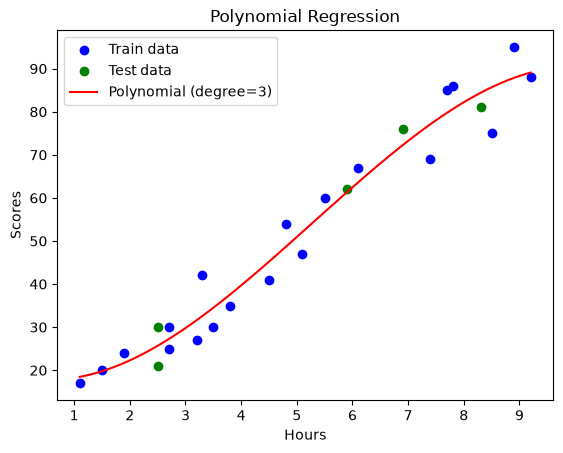

In [150]:
X_range = np.linspace(X.min(), X.max(), 200).reshape(-1, 1)
y_curve = model.predict(poly.transform(X_range))
 
plt.scatter(X_train, y_train, color="blue", label="Train data")
plt.scatter(X_test, y_test, color="green", label="Test data")
plt.plot(X_range, y_curve, color="red", label=f"Polynomial (degree={degree})")
plt.xlabel("Hours")
plt.ylabel("Scores")
plt.legend()
plt.title("Polynomial Regression")

In [151]:
hours = 7.5
pred = model.predict(poly.transform([[hours]]))
print(f"{hours} ghante -> {pred[0]:.1f} marks")

7.5 ghante -> 78.0 marks


d:\ML_regression\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


d:\ML_regression\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
d:\ML_regression\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


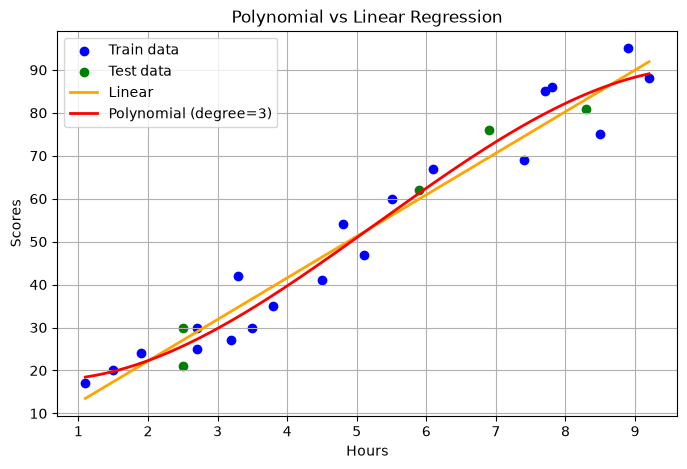

In [152]:

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

X_range = np.linspace(X.min(), X.max(), 200).reshape(-1, 1)

y_curve = model.predict(poly.transform(X_range))
y_linear = linear_model.predict(X_range)

plt.figure(figsize=(8, 5))
plt.scatter(X_train, y_train, color="blue", label="Train data")
plt.scatter(X_test, y_test, color="green", label="Test data")
plt.plot(X_range, y_linear, color="orange", linewidth=2, label="Linear")
plt.plot(X_range, y_curve, color="red", linewidth=2, label=f"Polynomial (degree={degree})")
plt.xlabel("Hours")
plt.ylabel("Scores")
plt.title("Polynomial vs Linear Regression")
plt.legend()
plt.grid(True)
plt.show()